# Predicting race winners
### Spotlight Sports Group — data science task

**Objective:** assign a win probability to each actual starter and select one horse per race. Each eligible race has one recognised winner. Predict near the start, assuming the final starter list and race conditions are known. Earlier declarations would require timestamped withdrawals and conditions.

**Final approach:** histogram gradient boosting with pre-race attributes, historical horse/trainer/jockey summaries and recent horse wins/DNFs. Histories use results from strictly earlier days; model parameters remain fixed during evaluation.

| Stage | Years | Purpose |
|---|---|---|
| Development training | 2021–2024 | Learn model parameters |
| Validation | 2025 | Compare features and approaches |
| Final training | 2021–2025 | Refit the locked configuration |
| Final test | 2026 | Evaluate sequential predictions |

**Evaluation disclosure:** an earlier logistic-regression baseline with frozen history was evaluated on 2026 before subsequent development. All subsequent feature/model comparisons used 2025. This final model is fixed before its 2026 evaluation; no changes are selected from the final test result. The test should not be described as never previously inspected.

**Run:** use the `model_candidates.csv.gz` export from the audit notebook and run top to bottom. Set the path in the next cell if needed. No database or source file is modified. Tested environment versions are printed below; this notebook does not require LightGBM or statsmodels.

In [ ]:
from pathlib import Path
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from IPython.display import display

# If needed, run in a separate cell: %pip install pandas numpy matplotlib "scikit-learn>=1.3"
INPUT_PATH_OVERRIDE = None  # e.g. Path(r'C:\Users\orman\Documents\horse-racing-assignment\outputs\audit_FOLDER\model_candidates.csv.gz')
EXPORT_RESULTS = False
SEED = 42
pd.set_option('display.max_columns',30)
pd.set_option('display.width',160)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':11})
print('Python:',platform.python_version(),'| pandas:',pd.__version__,'| scikit-learn:',sklearn.__version__)


Python: 3.14.6 | pandas: 3.0.6 | scikit-learn: 1.9.1


## 1. Modelling population
The audit retained complete, interpretable races with at least two starters and exactly one winner. Non-runners are excluded; recognised DNFs are non-winners. Races with ambiguous outcomes, disqualifications or multiple winners are excluded under the initial policy. These exclusions limit generalisation.

Load a feature allowlist plus outcome/history fields. Current-race ratings, margins and commentary are never loaded. Identifiers are restored as text and used for joins/grouping; raw horse, trainer and jockey IDs are not predictors. The favourite flag is reserved for the benchmark.

The checks below validate outcome labels and race membership, not predictor availability. Inspect the audit notebook for source-quality decisions and exclusion denominators.

In [11]:
if INPUT_PATH_OVERRIDE is not None:
    INPUT_PATH = Path(INPUT_PATH_OVERRIDE).expanduser().resolve()
else:
    roots = [Path.cwd(), Path.cwd().parent]
    candidates = set()
    for root in roots:
        for folder in [root, root/'data', root/'upload']:
            candidates.update(folder.glob('model_candidates.csv.gz'))
        if (root/'outputs').exists():
            candidates.update((root/'outputs').glob('audit_*/model_candidates.csv.gz'))
    candidates = sorted({p.resolve() for p in candidates})
    if len(candidates) != 1:
        raise FileNotFoundError(f'Set INPUT_PATH_OVERRIDE to the exact export. Found {len(candidates)} candidates.')
    INPUT_PATH = candidates[0]

ids = ['race_instance_uid','runner_uid','horse_uid','trainer_uid','jockey_uid','course_uid']
cat_features = ['horse_sex_code','country_origin_code','race_type_code','going_type_code',
                'direction_of_racing','country_code','course_uid']
cols = list(dict.fromkeys(ids + cat_features + ['event_datetime','year','is_winner','is_favourite',
        'horse_name','known_dnf','horse_age','draw','distance_furlong','race_class','field_size_actual']))
df = pd.read_csv(INPUT_PATH, usecols=cols, dtype={c:'string' for c in ids+cat_features})
df['event_datetime'] = pd.to_datetime(df['event_datetime'], errors='raise')
df['day'] = df.event_datetime.dt.normalize()
df = df.sort_values(['event_datetime','race_instance_uid','runner_uid']).reset_index(drop=True)
assert df.runner_uid.notna().all() and df.runner_uid.is_unique
assert not df.duplicated(['race_instance_uid','horse_uid']).any()
assert df.is_winner.isin([0,1]).all()
assert df.year.eq(df.event_datetime.dt.year).all()
assert df.year.between(2021,2026).all()
g = df.groupby('race_instance_uid')
assert g.is_winner.sum().eq(1).all()
assert g.day.nunique().eq(1).all()
assert g.field_size_actual.nunique().eq(1).all()
assert g.size().eq(g.field_size_actual.first()).all()
coverage = df.groupby('year').agg(starters=('runner_uid','size'), races=('race_instance_uid','nunique'),
                                 first_date=('day','min'),last_date=('day','max'))
display(coverage)
dnf_text=df.known_dnf.astype(str).str.lower()
assert dnf_text.isin(['true','false','1','0']).all(), 'Unexpected known_dnf value'
df['known_dnf']=dnf_text.isin(['true','1']).astype(int)
assert not (df.known_dnf.eq(1) & df.is_winner.eq(1)).any()
train=df.year.between(2021,2024)
valid=df.year.eq(2025)
refit=df.year.between(2021,2025)
test=df.year.eq(2026)
assert all(mask.any() for mask in [train,valid,refit,test])
assert set(df.loc[refit,'race_instance_uid']).isdisjoint(df.loc[test,'race_instance_uid'])


,starters,races,first_date,last_date
year,,,,
2021,29901,3046,2021-10-08,2021-12-31
2022,129043,14342,2022-01-01,2022-12-31
2023,128466,14046,2023-01-01,2023-12-31
2024,129800,13966,2024-01-01,2024-12-31
2025,126319,14139,2025-01-01,2025-12-31
2026,71156,7863,2026-01-01,2026-09-20


## 2. Predictors and historical information

| Feature group | Examples | Why included |
|---|---|---|
| Horse/race attributes | Age, sex, origin, draw, distance, race class, field size, month, course, going, race type, country and direction | Describe the runner and conditions |
| Cumulative history | Previous observed starts and smoothed win rate for horse, trainer and jockey | Summarise observed past success |
| Recency | Days since the horse's last observed start | Represent gaps between races |
| Within-race comparisons | Age and historical win rates relative to the field mean | Describe the competing field |
| Recent form | Wins and recognised DNFs in the last three observed starts; available-start count | Describe recent results without confusing missing history with losses |

Preprocessing rules: age outside 2–25, non-positive draw/distance/class are missing; missing categorical values and unseen categories are handled by the fitted pipeline. Race-shared features can interact with runner features in trees. `draw / field size` is a descriptive ratio, not a guaranteed percentile because stall numbering may have gaps.

**Leakage controls:** exclude current results, DNF/DQ status, comments, margins and unverified current-race Postmark/Topspeed ratings. Only *past* winner/DNF outcomes enter historical features. Training preprocessing never sees validation/test values. All same-day results are excluded from histories.

For a June 2026 race, results from earlier 2026 days can update history, while model parameters remain fitted on 2021–2025. This is sequential evaluation, not a single batch forecast made on 1 January. We assume results are available by the next day; actual publication/correction timestamps are unavailable. Full-dataset historical joins below are retrospective implementation of that rule: each joined summary must be strictly earlier than the prediction day.

History contains only eligible observed races, not complete careers. Smoothed win rate is `(wins + 1) / (starts + 10)`, a fixed 10% prior weighted as ten starts. New/missing identities get no observed history, rather than sharing a fictitious horse or trainer.

In [ ]:
features = df[cat_features].astype(object).where(df[cat_features].notna(), np.nan).copy()
features['horse_age'] = df.horse_age.where(df.horse_age.between(2,25))
features['draw'] = df.draw.where(df.draw.gt(0))
features['distance_furlong'] = df.distance_furlong.where(df.distance_furlong.gt(0))
features['race_class'] = df.race_class.where(df.race_class.gt(0))
features['field_size'] = df.field_size_actual
features['draw_per_runner'] = features.draw / features.field_size
features['month'] = df.event_datetime.dt.month

# Historical summaries are joined strictly before each prediction day, including during 2026.
history_source = df

def add_history(features, query_cutoff):
    out = features.copy()
    for entity, prefix in [('horse_uid','horse'),('trainer_uid','trainer'),('jockey_uid','jockey')]:
        daily = (history_source.dropna(subset=[entity]).groupby([entity,'day'], as_index=False)
                 .agg(starts=('is_winner','size'),wins=('is_winner','sum')))
        daily = daily.sort_values([entity,'day'])
        daily[['starts','wins']] = daily.groupby(entity)[['starts','wins']].cumsum()
        daily = daily.rename(columns={'day':'history_day'})
        query = pd.DataFrame({entity:df[entity], 'cutoff':query_cutoff, 'row':df.index}).dropna(subset=[entity])
        matched = pd.merge_asof(query.sort_values('cutoff'), daily.sort_values('history_day'),
                                left_on='cutoff',right_on='history_day',by=entity,
                                allow_exact_matches=False,direction='backward').set_index('row').reindex(df.index)
        assert (matched.history_day.isna() | matched.history_day.lt(query_cutoff)).all()
        starts = matched.starts.fillna(0)
        wins = matched.wins.fillna(0)
        out[prefix+'_log_starts'] = np.log1p(starts)
        out[prefix+'_win_rate'] = (wins+1)/(starts+10)
        out[prefix+'_no_history'] = starts.eq(0).astype(int)
        if prefix == 'horse':
            out['days_since_horse_race'] = (df.day-matched.history_day).dt.days
    for col in ['horse_age','horse_win_rate','trainer_win_rate','jockey_win_rate']:
        out[col+'_vs_field'] = out[col] - out[col].groupby(df.race_instance_uid).transform('mean')
    return out

X_base=add_history(features,df.day)

past=df.loc[df.horse_uid.notna(),['horse_uid','event_datetime','day','runner_uid','is_winner','known_dnf']].copy()
assert not past.duplicated(['horse_uid','event_datetime']).any(), 'Ambiguous simultaneous horse starts'
past=past.sort_values(['horse_uid','event_datetime','runner_uid'])
past['recent_wins']=past.groupby('horse_uid').is_winner.transform(lambda s:s.rolling(3,min_periods=1).sum())
past['recent_dnfs']=past.groupby('horse_uid').known_dnf.transform(lambda s:s.rolling(3,min_periods=1).sum())
past['recent_starts']=past.groupby('horse_uid').cumcount().add(1).clip(upper=3)
# Last summary of each day: only available to future days.
past=past.drop_duplicates(['horse_uid','day'],keep='last').rename(columns={'day':'history_day'})
recent_cols=['recent_wins','recent_dnfs','recent_starts']
query=df.loc[df.horse_uid.notna(),['horse_uid','day']].assign(row=lambda x:x.index)
matched=pd.merge_asof(query.sort_values('day'),past[['horse_uid','history_day']+recent_cols].sort_values('history_day'),
                      left_on='day',right_on='history_day',by='horse_uid',allow_exact_matches=False,
                      direction='backward').set_index('row').reindex(df.index)
assert (matched.history_day.isna() | matched.history_day.lt(df.day)).all()
X_recent=X_base.join(matched[recent_cols].fillna(0))
pd.testing.assert_frame_equal(X_recent[X_base.columns],X_base)
assert X_recent.recent_starts.between(0,3).all()
assert X_recent.recent_wins.add(X_recent.recent_dnfs).le(X_recent.recent_starts).all()
# Check direct history calculations independently for a reproducible sample.
rng=np.random.default_rng(SEED)
check_rows=rng.choice(df.index[df.horse_uid.notna()],size=30,replace=False)
horse_groups={horse:g for horse,g in df.loc[df.horse_uid.isin(df.loc[check_rows,'horse_uid'])].groupby('horse_uid')}
for idx in check_rows:
    row=df.loc[idx]
    history=horse_groups[row.horse_uid]
    earlier=history.loc[history.day.lt(row.day)].sort_values(['event_datetime','runner_uid']).tail(3)
    expected=[earlier.is_winner.sum(),earlier.known_dnf.sum(),len(earlier)]
    assert np.array_equal(X_recent.loc[idx,recent_cols].to_numpy(),expected)
X=X_recent
num_features=[c for c in X.columns if c not in cat_features]
assert X.shape[1]==31
print(f'{len(num_features)} numeric and {len(cat_features)} categorical predictors; temporal and history checks passed.')
display(X.loc[train,num_features].isna().mean().sort_values(ascending=False).head(6).rename('training_missing_fraction'))


## 3. Models and evaluation
**Logistic regression:** regularised additive baseline with median-imputed, standardised numeric features and one-hot categories. **Histogram gradient boosting:** nonlinear interactions, native numeric missingness handling and explicitly categorical encoded variables. Category imputation/encoding is fitted on training data only. No class weighting: we want probability estimates, not an artificially balanced class prior.

Both models are trained as runner-level classifiers. Positive-class scores are normalised within each race to sum to one. This preserves ranking but is not a joint race likelihood and does not guarantee calibration. The highest probability is selected, with ties broken consistently by runner ID.

| Metric | Interpretation | Direction |
|---|---|---|
| Winner selection | Fraction of races won by the top selection | Higher |
| Race log loss | Mean `−log(probability of the actual winner)` | Lower |
| Race Brier score | Mean over races of the sum of squared runner probability errors | Lower |

Every race has equal weight in evaluation; raw runner classification accuracy is inappropriate because most runners lose. Field sizes affect all these metrics, so compare models on the same races.

**Benchmarks:** uniform `1 / field size` probabilities, with *expected* random-selection accuracy; and selecting the flagged favourite. Joint favourites and races with no favourite use deterministic runner-ID tie-breaking, reported explicitly. No artificial win probabilities are assigned to the favourite flag, so no favourite log loss or Brier score is reported. The favourite snapshot is unverified and may have access to information unavailable to this model; it is not a timestamp-matched market experiment.

**Refit compatibility fix:** adding 2025 creates 259 course categories, exceeding the histogram model's 255-bin categorical limit. The ordinal encoder therefore keeps at most 255 encoded categories per feature by pooling the least frequent training categories. This rule uses training frequencies only, and unseen categories remain missing. Development-training category counts were below the cap, so the 2025 comparison is unaffected. The fix was made before generating the final test predictions. Requires scikit-learn with `OrdinalEncoder(max_categories=...)` support (tested with 1.8.0).

In [ ]:
def make_model(name):
    if name == 'Logistic regression':
        numeric = Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),
                            ('scale',StandardScaler())])
        categorical = Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                                ('encode',OneHotEncoder(handle_unknown='ignore'))])
        prep = ColumnTransformer([('num',numeric,num_features),('cat',categorical,cat_features)])
        estimator = LogisticRegression(C=1.0,max_iter=400,solver='lbfgs',random_state=SEED)
    else:
        categorical = Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                                ('encode',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=np.nan,max_categories=255))])
        prep = ColumnTransformer([('num','passthrough',num_features),('cat',categorical,cat_features)],sparse_threshold=0)
        estimator = HistGradientBoostingClassifier(max_iter=120,learning_rate=0.08,max_leaf_nodes=15,
                        min_samples_leaf=50,l2_regularization=5.0,early_stopping=False,
                        categorical_features=[False]*len(num_features)+[True]*len(cat_features),random_state=SEED)
    return Pipeline([('prepare',prep),('model',estimator)])

def normalise_scores(frame, scores):
    s = pd.Series(np.clip(scores,1e-12,1),index=frame.index)
    return s / s.groupby(frame.race_instance_uid).transform('sum')

def metrics(frame, probabilities):
    p = pd.Series(np.asarray(probabilities),index=frame.index)
    assert np.isfinite(p).all() and p.ge(0).all()
    assert np.allclose(p.groupby(frame.race_instance_uid).sum(),1)
    ranked = frame[['race_instance_uid','runner_uid','is_winner']].assign(probability=p)
    top = ranked.sort_values(['probability','runner_uid'],ascending=[False,True]).drop_duplicates('race_instance_uid')
    return {'races':len(top),'top_pick_win_rate':top.is_winner.mean(),
            'race_log_loss':-np.log(p[frame.is_winner.eq(1)].clip(lower=1e-15)).mean(),
            'race_brier':((p-frame.is_winner)**2).groupby(frame.race_instance_uid).sum().mean()}



## 4. Validation evidence and locked choice
The table below is an **experiment log from the executed supporting notebooks**, not a new search. The final feature comparison is reproduced immediately afterwards. Small accuracy differences should not be overstated.

| Features | Model | 2025 winner selection | Race log loss |
|---|---|---:|---:|
| Frozen history | Logistic regression | 23.78% | 2.01479 |
| Frozen history | Histogram gradient boosting | 23.69% | 2.0066 |
| Previous-day history | Logistic regression | 25.21% | 1.99047 |
| Previous-day history | Histogram gradient boosting | 25.55% | 1.97529 |
| Previous-day history + recent counts | Logistic regression | 25.55% | 1.98124 |
| Previous-day history + recent counts | Histogram gradient boosting | **25.86%** | **1.96849** |
| Same final features | LightGBM LambdaRank | 25.38% | Not applicable: ranking scores |

Updating history improved logistic-regression selection by 1.43 percentage points. Recent counts gave smaller selection gains (uncertainty intervals included zero) and improved log loss for both classifiers. The tested ranker provided no observed advantage. Its implementation also differs, so this does not isolate the effect of its training objective.

**Locked final model:** histogram gradient boosting, 120 iterations, learning rate 0.08, 15 leaves, minimum 50 samples per leaf, L2 regularisation 5, no early stopping. It led the tested configurations in both selection and probability metrics on 2025. No parameters will change after viewing 2026.

Supporting experiment files: `04_history_update_comparison.ipynb`, `05_recent_form_comparison.ipynb` and `06_race_ranker_comparison.ipynb`. They are optional evidence; this notebook runs independently.

In [ ]:
validation=df.loc[valid]
validation_rows=[]
for name in ['Logistic regression','Gradient boosting']:
    candidate=make_model(name)
    candidate.fit(X.loc[train],df.loc[train,'is_winner'])
    p=normalise_scores(validation,candidate.predict_proba(X.loc[valid])[:,1])
    validation_rows.append({'model':name,**metrics(validation,p)})
validation_results=pd.DataFrame(validation_rows).set_index('model')
display(validation_results.round(5))
FINAL_MODEL_NAME='Gradient boosting'  # Fixed from the validation experiments, not chosen from test metrics.


,races,top_pick_win_rate,race_log_loss,race_brier
model,,,,
Logistic regression,14139,0.25546,1.98124,0.83239
Gradient boosting,14139,0.25702,1.96933,0.82917


## 5. Final refit and sequential 2026 evaluation
Fit preprocessing and model parameters on all eligible 2021–2025 starters. Predict 2026 using features as of each race day, incorporating earlier-day outcomes only. Historical updating is not parameter retraining.

The audit identified unresolved results concentrated in February–April 2026. This file contains only retained races; it cannot supply the full denominator for retention. Results apply to this filtered population. No post-test feature/model changes are made.

In [ ]:
final_model=make_model(FINAL_MODEL_NAME)
final_model.fit(X.loc[refit],df.loc[refit,'is_winner'])
holdout=df.loc[test].copy()
p_model=normalise_scores(holdout,final_model.predict_proba(X.loc[test])[:,1])
p_uniform=1/holdout.field_size_actual
flag_text=holdout.is_favourite.astype(str).str.lower()
assert flag_text.isin(['true','false','1','0']).all()
fav_flag=flag_text.isin(['true','1'])

def race_picks(frame,score):
    ranked=frame[['race_instance_uid','runner_uid','day','is_winner']].assign(score=score)
    return ranked.sort_values(['score','runner_uid'],ascending=[False,True]).drop_duplicates('race_instance_uid').set_index('race_instance_uid').sort_index()

model_picks=race_picks(holdout,p_model)
fav_picks=race_picks(holdout,fav_flag.astype(float))
random_metrics=metrics(holdout,p_uniform)
# Replace arbitrary tied uniform selection with the expected random selection rate.
random_metrics['top_pick_win_rate']=(1/holdout.groupby('race_instance_uid').field_size_actual.first()).mean()
final_results=pd.DataFrame([
    {'approach':'Random / uniform',**random_metrics},
    {'approach':'Favourite selection','races':len(fav_picks),'top_pick_win_rate':fav_picks.is_winner.mean(),'race_log_loss':np.nan,'race_brier':np.nan},
    {'approach':'Final gradient boosting',**metrics(holdout,p_model)}
]).set_index('approach')
display(final_results.round(5))
fav_counts=fav_flag.groupby(holdout.race_instance_uid).sum()
print('Favourite counts per test race:',{'none':int(fav_counts.eq(0).sum()),'single':int(fav_counts.eq(1).sum()),'multiple':int(fav_counts.gt(1).sum())})

predictions=holdout[['race_instance_uid','runner_uid','horse_uid','horse_name','event_datetime','race_type_code','field_size_actual','is_winner']].copy()
predictions['win_probability']=p_model
ordered=predictions.sort_values(['win_probability','runner_uid'],ascending=[False,True])
predictions['rank']=ordered.groupby('race_instance_uid').cumcount().add(1).reindex(predictions.index)
assert predictions.groupby('race_instance_uid').win_probability.sum().sub(1).abs().lt(1e-10).all()
assert predictions.loc[predictions['rank'].eq(1)].is_winner.mean()==final_results.loc['Final gradient boosting','top_pick_win_rate']


,races,top_pick_win_rate,race_log_loss,race_brier
approach,,,,
Random / uniform,7863,0.12997,2.12463,0.87003
Favourite selection,7863,0.35152,NaN,NaN
Final gradient boosting,7863,0.25639,1.98935,0.83430


Favourite counts per test race: {'none': 11, 'single': 7258, 'multiple': 594}


## 6. Performance figures and uncertainty
Use winner selection and log loss together. No odds-based profitability or market-calibration claims are possible from the favourite flag. The probability comparison is against a uniform baseline, not actual market probabilities.

The date-block bootstrap resamples whole test days, keeping model and favourite results paired. Intervals describe variability in the retained test period and do not capture all dependence across dates, missing-data bias or development-selection uncertainty.

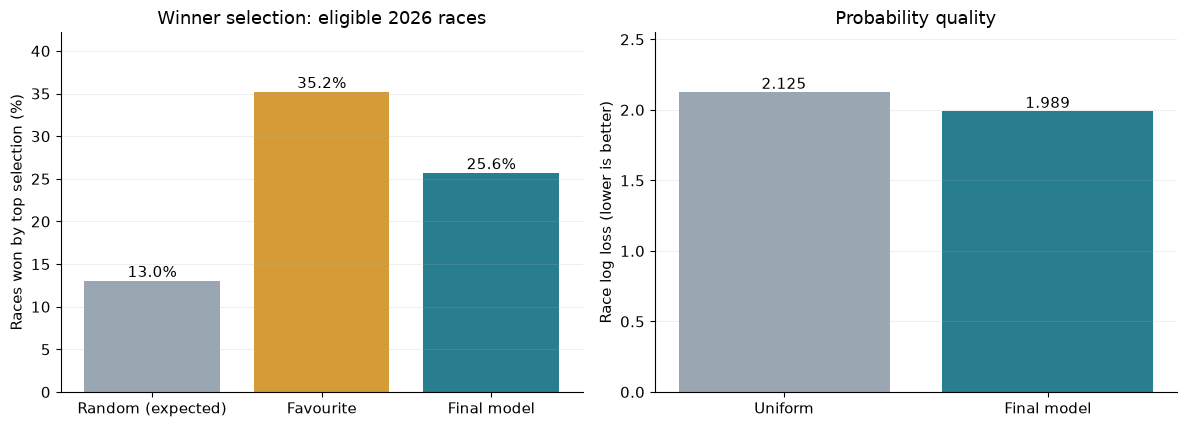

95% date-block interval for model selection rate (%): [24.68 26.6 ]
95% paired interval for model minus favourite (percentage points): [-10.66  -8.41]


In [ ]:
fig_performance,axes=plt.subplots(1,2,figsize=(12,4.4))
labels=['Random (expected)','Favourite','Final model']
values=100*final_results.top_pick_win_rate
axes[0].bar(labels,values,color=['#9AA6B2','#D59B37','#287D8E'])
for i,v in enumerate(values):axes[0].text(i,v+.5,f'{v:.1f}%',ha='center')
axes[0].set(title='Winner selection: eligible 2026 races',ylabel='Races won by top selection (%)',ylim=(0,max(values)*1.2))
prob_results=final_results.loc[['Random / uniform','Final gradient boosting']]
axes[1].bar(['Uniform','Final model'],prob_results.race_log_loss,color=['#9AA6B2','#287D8E'])
for i,v in enumerate(prob_results.race_log_loss):axes[1].text(i,v+.025,f'{v:.3f}',ha='center')
axes[1].set(title='Probability quality',ylabel='Race log loss (lower is better)',ylim=(0,prob_results.race_log_loss.max()*1.2))
for ax in axes:ax.grid(axis='y',alpha=.2)
fig_performance.tight_layout();plt.show()

paired=model_picks[['day','is_winner']].rename(columns={'is_winner':'model_correct'})
paired['favourite_correct']=fav_picks.is_winner
paired['difference']=paired.model_correct-paired.favourite_correct
daily=paired.groupby('day').agg(n=('model_correct','size'),model=('model_correct','sum'),difference=('difference','sum'))
rng=np.random.default_rng(SEED);bootstrap=[]
for _ in range(2000):
    sample=daily.iloc[rng.integers(0,len(daily),len(daily))]
    bootstrap.append([sample.model.sum()/sample.n.sum(),sample.difference.sum()/sample.n.sum()])
interval=np.quantile(bootstrap,[.025,.975],axis=0)
print('95% date-block interval for model selection rate (%):',np.round(100*interval[:,0],2))
print('95% paired interval for model minus favourite (percentage points):',np.round(100*interval[:,1],2))


## 7. Calibration and coverage diagnostics
Calibration asks whether horses assigned, for example, a 20% win probability win about 20% of the time. The chart pools runners into ten equal-frequency bins. It can conceal differences by field size or race type; it is descriptive and not used to recalibrate on the test set.

Context tables and monthly retained counts describe where the result applies. They do not recover excluded races and are not used to tune the final model.

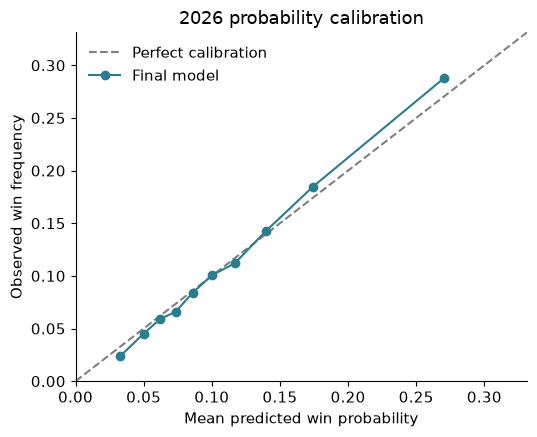

,races,top_pick_win_rate,race_log_loss,race_brier,favourite_selection
race_type,,,,,
C,748,0.2594,1.8492,0.8148,0.3650
F,5295,0.2533,2.0137,0.8404,0.3449
H,1388,0.2529,2.0291,0.8329,0.3523
HF,175,0.2857,1.9269,0.8178,0.3657
P,257,0.3113,1.7240,0.7837,0.4358


,eligible_races,starters
day,,
2026-01,939,8362
2026-02,780,6390
2026-03,21,200
2026-04,541,5096
2026-05,1346,12361
2026-06,1148,10520
2026-07,1224,10820
2026-08,1112,10098
2026-09,752,7309


In [ ]:
cal=predictions.assign(bin=pd.qcut(predictions.win_probability,10,duplicates='drop'))
calibration=cal.groupby('bin',observed=True).agg(predicted=('win_probability','mean'),observed=('is_winner','mean'),runners=('is_winner','size'))
fig_calibration,ax=plt.subplots(figsize=(5.5,4.5))
limit=max(calibration.predicted.max(),calibration.observed.max())*1.15
ax.plot([0,limit],[0,limit],'--',color='grey',label='Perfect calibration')
ax.plot(calibration.predicted,calibration.observed,'o-',color='#287D8E',label='Final model')
ax.set(xlim=(0,limit),ylim=(0,limit),xlabel='Mean predicted win probability',ylabel='Observed win frequency',title='2026 probability calibration')
ax.legend(frameon=False);fig_calibration.tight_layout();plt.show()

context=[]
for kind,idx in holdout.groupby('race_type_code').groups.items():
    part=holdout.loc[idx]
    context.append({'race_type':kind,**metrics(part,p_model.loc[idx]),
                    'favourite_selection':race_picks(part,fav_flag.loc[idx].astype(float)).is_winner.mean()})
context_results=pd.DataFrame(context).set_index('race_type')
display(context_results.round(4))
monthly=holdout.groupby(holdout.day.dt.to_period('M')).agg(eligible_races=('race_instance_uid','nunique'),starters=('runner_uid','size'))
display(monthly)


## 8. Interpretation and practical limits
**Recorded final run:** winner selection was **25.54%** on **7,863** eligible 2026 races (95% date-block interval: **24.53–26.55%**), versus **13.00%** expected random selection and **35.15%** favourite selection. Race log loss improved from **2.1246** for uniform probabilities to **1.9901**; race Brier score improved from **0.8700** to **0.8345**. The model remained **9.61 percentage points below favourite selection**, so these results do not support replacing that benchmark for winner picking.

The next cell summarises the observed final metrics dynamically so the narrative remains aligned with the run. Evaluate both the gain over uniform predictions and the gap to favourite selection. Beating random selection alone does not demonstrate product value or profitability.

**What this experiment establishes:** a reproducible, temporally evaluated baseline and evidence about the tested feature/model changes. It does not establish causal effects of horse/trainer characteristics or competitive performance against a timestamp-matched odds model.

**Main limitations:** incomplete observed careers; partial calendar-year coverage; filtered and seasonally uneven 2026 races; no verified pre-race ratings, carried weight or odds; assumed next-day result availability; normalised binary scores rather than a joint race probability model; one validation year and modest model exploration. Prediction presumes known actual starters. The retrospective audit's eligibility decisions use results; they define an evaluation population, not a pre-race rule for knowing which future races will have clean data.

**With more time:** verify pre-race feature snapshots; add lagged ratings and richer condition-specific form; evaluate with rolling-year validation; assess probability calibration using pre-test data; compare against timestamped market odds and test incremental value. The ranking experiment was useful but did not outperform the chosen classifier under its tested settings.

**Product perspective:** ranked previews and uncertainty estimates are possible uses, but deployment requires evidence of value beyond existing favourites/odds, monitoring and dependable feature availability. A live interface must supply every declared runner's pre-race attributes plus a historical store; it must never require current-race outcomes.

**Reproducibility:** source data remain unchanged. Export below optionally saves metrics, predictions and figures to a new timestamped folder. This notebook is the main submission entry point; experiment notebooks are supporting evidence.

In [ ]:
model_result=final_results.loc['Final gradient boosting']
random_result=final_results.loc['Random / uniform']
favourite_result=final_results.loc['Favourite selection']
print(f"Final model: {100*model_result.top_pick_win_rate:.2f}% correct selections across {int(model_result.races):,} eligible 2026 races.")
print(f"Expected random selection: {100*random_result.top_pick_win_rate:.2f}%; favourite selection: {100*favourite_result.top_pick_win_rate:.2f}%.")
print(f"Model minus favourite: {100*(model_result.top_pick_win_rate-favourite_result.top_pick_win_rate):+.2f} percentage points.")
print(f"Race log loss: {model_result.race_log_loss:.4f}, versus {random_result.race_log_loss:.4f} for uniform probabilities.")
print(f"Race Brier: {model_result.race_brier:.4f}, versus {random_result.race_brier:.4f} for uniform probabilities.")
if model_result.top_pick_win_rate < favourite_result.top_pick_win_rate:
    print('The model learns useful signal if it improves on uniform predictions, but does not beat favourite selection in this test.')
print('No model or feature choices are changed in response to these test results.')

if EXPORT_RESULTS:
    out=Path.cwd()/'outputs'/('winner_submission_'+pd.Timestamp.now().strftime('%Y%m%d_%H%M%S_%f'))
    out.mkdir(parents=True,exist_ok=False)
    validation_results.to_csv(out/'validation_metrics.csv')
    final_results.to_csv(out/'test_metrics.csv')
    context_results.to_csv(out/'test_context_metrics.csv')
    monthly.to_csv(out/'test_monthly_counts.csv')
    predictions.to_csv(out/'test_predictions.csv.gz',index=False,compression='gzip')
    fig_performance.savefig(out/'test_performance.png',dpi=180,bbox_inches='tight')
    fig_calibration.savefig(out/'test_calibration.png',dpi=180,bbox_inches='tight')
    print('Saved:',out.resolve())


Final model: 25.64% correct selections across 7,863 eligible 2026 races.
Expected random selection: 13.00%; favourite selection: 35.15%.
Model minus favourite: -9.51 percentage points.
Race log loss: 1.9894, versus 2.1246 for uniform probabilities.
Race Brier: 0.8343, versus 0.8700 for uniform probabilities.
The model learns useful signal if it improves on uniform predictions, but does not beat favourite selection in this test.
No model or feature choices are changed in response to these test results.
